<a href="https://colab.research.google.com/github/hoangvvthu/machine_learning/blob/main/_downloads/Model3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phân loại ảnh CIFAR-10 — Model 3

Theo luồng CIFAR-10: **dữ liệu → CNN → loss/SGD → huấn luyện → kiểm tra**. Ba notebook cùng cách trình bày: Kaiming cho Conv có ReLU, FC giữ mặc định PyTorch.

**Đã chạy lại từ đầu ngày 16/10/2026** trên RTX 3050: 50.000 ảnh train, 10.000 ảnh test, batch 4, SGD(lr=0.001, momentum=0.9), seed 42, đủ 10 epochs. Output và biểu đồ bên dưới là kết quả của lần chạy này.

| Thông số | Kết quả |
|---|---:|
| Số tham số | 10,417,189 |
| Số epochs đã chạy | 10 |
| Train Accuracy cuối | 91.33% |
| Test Accuracy | 75.79% |
| Test Loss | 0.9771 |

Có thể đọc output đã lưu mà không cần train lại. Khi chạy lại, dùng GPU và chạy các cell theo thứ tự; kết quả có thể khác theo thiết bị/phiên bản PyTorch.

**Nhận xét:** train cao hơn test 15.54 điểm phần trăm, cho thấy model học dữ liệu train tốt hơn khả năng tổng quát trên test (overfit). Train accuracy cao không bảo đảm test accuracy cao.


## 1. Nạp và quan sát dữ liệu CIFAR-10

CIFAR-10 có 50.000 ảnh train và 10.000 ảnh test, mỗi ảnh RGB 32×32. `ToTensor()` đưa ảnh về tensor; `Normalize` đổi miền giá trị về khoảng [-1,1]. Batch 4; train xáo trộn, test giữ thứ tự. `device` chọn GPU khi có CUDA.


In [88]:
%pip -q install torchsummary==1.5.1

In [89]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
print("Device:", device)
print("PyTorch version:", torch.__version__)

model_number = 3


In [90]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 4
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2,
    pin_memory=(device.type == "cuda")
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=2,
    pin_memory=(device.type == "cuda")
)

classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
print("Training images:", len(trainset))
print("Testing images:", len(testset))
print("Batch size:", batch_size)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training images: 50000
Testing images: 10000


horse   car  ship   cat


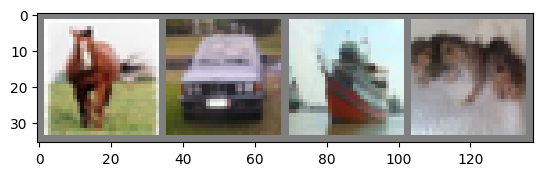

In [91]:
def imshow(image):
    image = image / 2 + 0.5             # Đổi ảnh từ [-1,1] về [0,1] để hiển thị đúng màu.
    image = image.clamp(0, 1)
    plt.figure(figsize=(9, 3))
    plt.imshow(np.transpose(image.numpy(), (1, 2, 0)))
    plt.axis("off")
    plt.show()

images, labels = next(iter(trainloader))
print("Input shape:", tuple(images.shape))
print("Ground truth:", " ".join(classes[label.item()] for label in labels))
imshow(torchvision.utils.make_grid(images))


## 2. Khai báo mạng CNN — Model 3

10 Conv 3×3 + 10 Conv 5×5, 4 lượt MaxPool, 3 ADD, 3 CAT, 2 SPLIT và 3 FC. `__init__()` khai báo lớp; `forward()` xác định đường đi của tensor. Dùng `x` cho luồng đang xử lý, `x1`/`x2` để giữ nhánh cần dùng lại.

`[B,C,H,W]`: batch, kênh, chiều cao, chiều rộng. **ADD** cộng tensor cùng shape; **CAT** nối kênh; **SPLIT** chia kênh. Flatten trải C×H×W thành một vector cho mỗi ảnh.

| Cụm kiến trúc | Phép biến đổi | Shape đầu ra |
|---|---|---|
| Conv1 → Conv2/Conv3 | 3→6; hai nhánh 6→12 | `[B, 12, 32, 32]` mỗi nhánh |
| MaxPool1/2 → ADD1 | 32×32 → 16×16; cộng hai nhánh | `[B, 12, 16, 16]` |
| Conv4 → CAT1 | 12→24; CAT(MaxPool1 12, Conv4 24) | `[B, 36, 16, 16]` |
| Conv5→7→9 và Conv6→8→10 | Mỗi nhánh 36→72→80→85 | `[B, 85, 16, 16]` mỗi nhánh |
| CAT2 → MaxPool3 → Conv11 → MaxPool4 | 85+85=170; 16→8→4 | `[B, 170, 4, 4]` |
| SPLIT1 → Conv12…14 / Conv15…17 → ADD2 | 170→85+85; hai nhánh đến 100 rồi cộng | `[B, 100, 4, 4]` |
| SPLIT2 → Conv18/Conv19 → ADD3 | 100→50+50; hai nhánh đến 60 rồi cộng | `[B, 60, 4, 4]` |
| Conv20 / CAT3 | 60→65; CAT(Conv20 65, Conv19 60) | `[B, 125, 4, 4]` |
| Flatten → ba lớp FC | 125×4×4=2000; 2000→1990→1950→10 | `[B, 10]` |

Ba model đều dùng cùng cách khởi tạo: Kaiming cho Conv, mặc định cho FC. FC cuối tạo 10 logits, không qua ReLU hoặc Softmax trước `CrossEntropyLoss`.


In [133]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        # Conv khai báo số kênh vào/ra, kernel, stride, padding; forward xác định đường nối.
        self.conv1 = nn.Conv2d(3, 6, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(6, 12, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(6, 12, kernel_size=3, stride=1, padding=1)
        self.conv4 = nn.Conv2d(12, 24, kernel_size=3, stride=1, padding=1)
        self.conv5 = nn.Conv2d(36, 72, kernel_size=3, stride=1, padding=1)
        self.conv6 = nn.Conv2d(36, 72, kernel_size=3, stride=1, padding=1)
        self.conv7 = nn.Conv2d(72, 80, kernel_size=3, stride=1, padding=1)
        self.conv8 = nn.Conv2d(72, 80, kernel_size=3, stride=1, padding=1)
        self.conv9 = nn.Conv2d(80, 85, kernel_size=3, stride=1, padding=1)
        self.conv10 = nn.Conv2d(80, 85, kernel_size=3, stride=1, padding=1)
        self.conv11 = nn.Conv2d(170, 170, kernel_size=5, stride=1, padding=2)
        self.conv12 = nn.Conv2d(85, 90, kernel_size=5, stride=1, padding=2)
        self.conv13 = nn.Conv2d(90, 95, kernel_size=5, stride=1, padding=2)
        self.conv14 = nn.Conv2d(95, 100, kernel_size=5, stride=1, padding=2)
        self.conv15 = nn.Conv2d(85, 90, kernel_size=5, stride=1, padding=2)
        self.conv16 = nn.Conv2d(90, 95, kernel_size=5, stride=1, padding=2)
        self.conv17 = nn.Conv2d(95, 100, kernel_size=5, stride=1, padding=2)
        self.conv18 = nn.Conv2d(50, 60, kernel_size=5, stride=1, padding=2)
        self.conv19 = nn.Conv2d(50, 60, kernel_size=5, stride=1, padding=2)
        self.conv20 = nn.Conv2d(60, 65, kernel_size=5, stride=1, padding=2)
        # Cùng module MaxPool có thể được gọi ở nhiều vị trí trong forward.
        self.pool = nn.MaxPool2d(2, 2)
        # FC1 nhận vector Flatten; lớp FC cuối tạo 10 logits.
        self.fc1 = nn.Linear(125 * 4 * 4, 1990)
        self.fc2 = nn.Linear(1990, 1950)
        self.fc3 = nn.Linear(1950, 10)

        # ReLU: khởi tạo Conv bằng Kaiming để tín hiệu qua mạng sâu ổn định hơn.
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        # KHỐI 1: Ảnh RGB -> Conv1: [B,3,32,32] -> [B,6,32,32].
        x = F.relu(self.conv1(x))

        # KHỐI 2: Giữ MaxPool1 trong x1 để ghép CAT1; x tiếp tục qua ADD1.
        x1 = self.pool(F.relu(self.conv2(x)))  # MaxPool1: [B,12,16,16].
        x = self.pool(F.relu(self.conv3(x)))   # MaxPool2: [B,12,16,16].
        x = x1 + x                            # ADD1: [B,12,16,16].
        x = F.relu(self.conv4(x))              # Conv4 lấy ADD1: 12 -> 24.
        x = torch.cat((x1, x), dim=1)          # CAT1 = MaxPool1 12 + Conv4 24 = 36.

        # KHỐI 3: Hai nhánh cùng nhận CAT1; mỗi nhánh qua ba Conv 3*3.
        x1 = F.relu(self.conv5(x))             # Conv5: 36 -> 72.
        x = F.relu(self.conv6(x))              # Conv6: 36 -> 72.
        x1 = F.relu(self.conv7(x1))            # Conv5 -> Conv7: 72 -> 80.
        x = F.relu(self.conv8(x))              # Conv6 -> Conv8: 72 -> 80.
        x1 = F.relu(self.conv9(x1))            # Conv7 -> Conv9: 80 -> 85.
        x = F.relu(self.conv10(x))             # Conv8 -> Conv10: 80 -> 85.
        x = torch.cat((x1, x), dim=1)          # CAT2 = Conv9 85 + Conv10 85 = 170.

        # KHỐI 4: MaxPool3 -> Conv11 -> MaxPool4, H,W: 16 -> 8 -> 4.
        x = self.pool(x)                      # MaxPool3: [B,170,8,8].
        x = F.relu(self.conv11(x))             # Conv11 giữ [B,170,8,8].
        x = self.pool(x)                      # MaxPool4: [B,170,4,4].

        # KHỐI 5: SPLIT1 chia 170 thành 85+85; dùng x và x1 cho hai nhánh.
        x, x1 = torch.chunk(x, 2, dim=1)
        x = F.relu(self.conv12(x))             # 85 -> 90.
        x = F.relu(self.conv13(x))             # 90 -> 95.
        x = F.relu(self.conv14(x))             # 95 -> 100.
        x1 = F.relu(self.conv15(x1))           # 85 -> 90.
        x1 = F.relu(self.conv16(x1))           # 90 -> 95.
        x1 = F.relu(self.conv17(x1))           # 95 -> 100.
        x = x + x1                            # ADD2: [B,100,4,4].

        # KHỐI 6: SPLIT2 chia 100 thành 50+50; giữ Conv19 trong x1 cho CAT3.
        x, x1 = torch.chunk(x, 2, dim=1)
        x = F.relu(self.conv18(x))             # Conv18: 50 -> 60.
        x1 = F.relu(self.conv19(x1))           # Conv19: 50 -> 60.
        x = x + x1                            # ADD3: [B,60,4,4].
        x = F.relu(self.conv20(x))             # Conv20 lấy ADD3: 60 -> 65.
        x = torch.cat((x, x1), dim=1)          # CAT3 = Conv20 65 + Conv19 60 = 125.

        # KHỐI 7: Flatten -> đúng ba lớp FC.
        x = torch.flatten(x, 1)               # 125*4*4 = 2000 đặc trưng/ảnh.
        x = F.relu(self.fc1(x))               # 2000 -> 1990.
        x = F.relu(self.fc2(x))               # 1990 -> 1950.
        x = self.fc3(x)                       # [B,10]: 10 logits.
        return x


from torchsummary import summary
net = Net().to(device)
summary(net, (3, 32, 32))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 6, 32, 32]             168
            Conv2d-2           [-1, 12, 32, 32]             660
         MaxPool2d-3           [-1, 12, 16, 16]               0
            Conv2d-4           [-1, 12, 32, 32]             660
         MaxPool2d-5           [-1, 12, 16, 16]               0
            Conv2d-6           [-1, 24, 16, 16]           2,616
            Conv2d-7           [-1, 72, 16, 16]          23,400
            Conv2d-8           [-1, 72, 16, 16]          23,400
            Conv2d-9           [-1, 80, 16, 16]          51,920
           Conv2d-10           [-1, 80, 16, 16]          51,920
           Conv2d-11           [-1, 85, 16, 16]          61,285
           Conv2d-12           [-1, 85, 16, 16]          61,285
        MaxPool2d-13            [-1, 170, 8, 8]               0
           Conv2d-14            [-1, 17

Bảng `Layer (type) – Output Shape – Param #` cho biết các lớp được gọi, shape đầu ra và số tham số. `-1` đại diện batch bất kỳ. ADD/CAT/SPLIT viết bằng hàm nên xem đường nối trong `forward()` và sơ đồ đi kèm.

`net = Net().to(device)` tạo mạng và đưa lên cùng thiết bị với ảnh. `.to(device)` giúp ba dòng theo mẫu chạy đúng khi bật GPU.


Đoạn `for layer in self.modules()` chạy một lần khi tạo `Net()`: duyệt các lớp, chọn Conv, đặt weights theo Kaiming cho ReLU và bias bằng 0. Đây là hàm có sẵn trong `torch.nn.init`; kiến trúc và số tham số giữ nguyên. Bản mặc định của Model 3 trước đó có loss gần 2,303 và accuracy quanh 10%; thử nghiệm ngắn chỉ trên train cho thấy cách khởi tạo này giúp loss giảm. Ba model được train mới hoàn toàn để so sánh cùng cấu hình.

Nguồn: [PyTorch CIFAR-10 tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) và [torch.nn.init.kaiming_normal_](https://docs.pytorch.org/docs/stable/nn.init.html#torch.nn.init.kaiming_normal_).


## 3. Hàm mất mát và bộ tối ưu

`CrossEntropyLoss` so sánh logits với nhãn thật. Cả ba model dùng SGD với `lr=0.001`, `momentum=0.9`, `weight_decay=0`.


In [134]:
learning_rate = 0.001
momentum = 0.9
weight_decay = 0.0

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    net.parameters(), lr=learning_rate, momentum=momentum, weight_decay=weight_decay
)

print("Loss function:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", learning_rate)
print("Momentum:", momentum)
print("Weight decay:", weight_decay)

Loss function: CrossEntropyLoss
Optimizer: SGD
Learning rate: 0.001
Momentum: 0.9
Weight decay: 0.0


## 4. Huấn luyện mạng

Mỗi batch: **xóa gradient → forward → tính loss → backward → cập nhật weights**. Chạy 10 epochs. Loss/accuracy dưới đây được tính trên train trong lúc model học.


In [ ]:
num_epochs = 1
train_loss_history = []
train_accuracy_history = []

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in trainloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        outputs = net(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct_predictions += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = 100.0 * correct_predictions / total_samples
    train_loss_history.append(epoch_loss)
    train_accuracy_history.append(epoch_accuracy)
    print(f"Epoch [{epoch + 1}/{num_epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_accuracy:.2f}%")

print("Finished Training")

### Biểu đồ huấn luyện

Theo dõi loss và accuracy theo epoch; kết quả test được tính riêng ở phần 5.


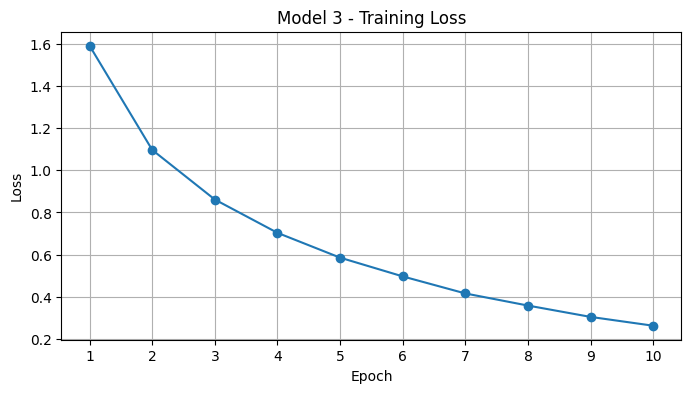

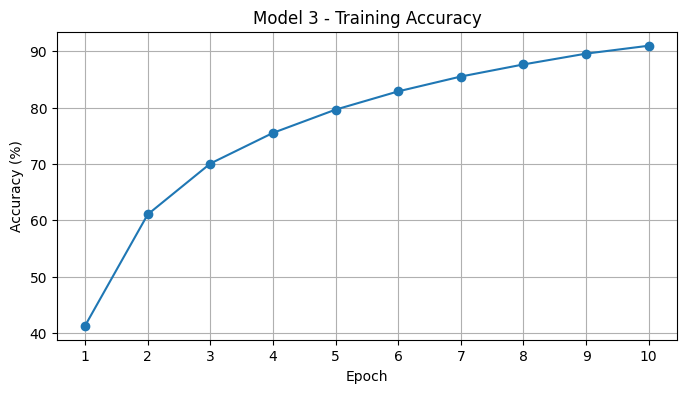

In [95]:
epochs = range(1, len(train_loss_history) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_loss_history, marker="o")
plt.title(f"Model {model_number} - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_accuracy_history, marker="o")
plt.title(f"Model {model_number} - Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(list(epochs))
plt.grid(True)
plt.show()

## 5. Kiểm tra trên dữ liệu test

Xem nhãn thật và dự đoán của một batch. Mỗi ảnh có 10 logits; `argmax(dim=1)` chọn lớp có điểm lớn nhất.


Ground truth: cat ship ship plane
Predicted:    cat ship ship plane


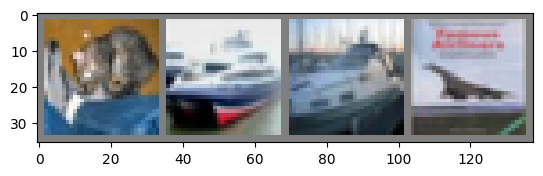

In [132]:
test_images, test_labels = next(iter(testloader))
imshow(torchvision.utils.make_grid(test_images))

net.eval()
with torch.no_grad():
    test_outputs = net(test_images.to(device))
predicted_classes = test_outputs.argmax(dim=1).cpu()

print("Ground truth:", " ".join(classes[label.item()] for label in test_labels))
print("Predicted:   ", " ".join(classes[label.item()] for label in predicted_classes))

### 5.1. Đánh giá toàn bộ 10.000 ảnh test

`eval()` đặt chế độ đánh giá; `no_grad()` tắt tính gradient. Phần này không cập nhật weights.


In [123]:
net.eval()
running_test_loss = 0.0
correct_test_predictions = 0
total_test_samples = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = net(images)
        loss = criterion(outputs, labels)
        running_test_loss += loss.item() * labels.size(0)
        correct_test_predictions += (outputs.argmax(dim=1) == labels).sum().item()
        total_test_samples += labels.size(0)

test_loss = running_test_loss / total_test_samples
test_accuracy = 100.0 * correct_test_predictions / total_test_samples
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 0.8378
Test Accuracy: 76.20%


### 5.2. Kết quả từng lớp

Mỗi lớp test có 1.000 ảnh. Tỷ lệ dưới đây là số nhận đúng chia cho số ảnh có nhãn thật thuộc lớp đó.


In [124]:
class_correct = [0] * len(classes)
class_total = [0] * len(classes)

net.eval()
with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        predictions = net(images).argmax(dim=1)
        for label, prediction in zip(labels.cpu(), predictions.cpu()):
            index = label.item()
            class_total[index] += 1
            class_correct[index] += int(prediction.item() == index)

class_accuracy = []
for index, name in enumerate(classes):
    accuracy = 100.0 * class_correct[index] / class_total[index]
    class_accuracy.append(accuracy)
    print(f"{name:>10}: {accuracy:6.2f}% ({class_correct[index]}/{class_total[index]})")

     plane:  81.50% (815/1000)
       car:  87.10% (871/1000)
      bird:  69.00% (690/1000)
       cat:  58.60% (586/1000)
      deer:  67.70% (677/1000)
       dog:  64.70% (647/1000)
      frog:  79.00% (790/1000)
     horse:  81.40% (814/1000)
      ship:  88.60% (886/1000)
     truck:  84.40% (844/1000)


### 5.3. Tổng kết

Số liệu được lấy từ các biến vừa tính. Train Accuracy cao chưa bảo đảm Test Accuracy cao; kết quả có thể thay đổi giữa các lần chạy.


In [125]:
total_params = sum(parameter.numel() for parameter in net.parameters())
best_class = max(range(len(classes)), key=lambda index: class_accuracy[index])
worst_class = min(range(len(classes)), key=lambda index: class_accuracy[index])

print(f"===== Model {model_number} Summary =====")
print(f"Total parameters: {total_params:,}")
print(f"Completed epochs: {len(train_loss_history)}")
print(f"Final training loss: {train_loss_history[-1]:.4f}")
print(f"Final training accuracy: {train_accuracy_history[-1]:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2f}%")
print(f"Train-test accuracy gap: {train_accuracy_history[-1] - test_accuracy:.2f} percentage points")
print(f"Best class: {classes[best_class]} ({class_accuracy[best_class]:.2f}%)")
print(f"Lowest class: {classes[worst_class]} ({class_accuracy[worst_class]:.2f}%)")


===== Model 3 Summary =====
Total parameters: 10,417,189
Completed epochs: 10
Final training loss: 0.2622
Final training accuracy: 91.00%
Test loss: 0.8378
Test accuracy: 76.20%
Train-test accuracy gap: 14.80 percentage points
Best class: ship (88.60%)
Lowest class: cat (58.60%)
